# Step 4 - Churn Prediction Models
**Objective 2:** train and compare classification models that predict customer churn, then calibrate their probabilities (Step 8 will use them to decide who to target).

**Input:** `data/churn_dataset.csv` from Step 3. Click **Run All** (takes a few minutes).

| Part | What happens |
|---|---|
| Split | **By time, not randomly.** Train on the 4 snapshots of 2010, test once on the 1 Jul 2011 snapshot |
| Models | Logistic Regression (baseline), Random Forest, and a gradient-boosting model (XGBoost, or LightGBM / scikit-learn boosting if XGBoost is not installed) |
| Tuning | Hyper-parameters are chosen with 5-fold cross-validation **grouped by customer**, so the same customer is never in both the training and validation fold |
| Metrics | ROC-AUC, PR-AUC, F1, precision, recall (plus Brier score and calibration error) |
| Calibration | Probabilities are recalibrated (none / sigmoid / isotonic, whichever works best in cross-validation) so that "0.70" really means about 70% |
| Fairness to the test set | The test snapshot is used **once**, at the end. Model choice, calibration method and decision threshold are all decided on training data only |

**Outputs:** `data/model_comparison.csv`, `data/churn_predictions_test.csv`, `models/churn_models.joblib`, `models/churn_scoring.py`, and charts in `figures/`.

## 1. Setup and data

In [5]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             brier_score_loss, log_loss, roc_curve, precision_recall_curve, confusion_matrix)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA, FIG, MODELS = "data", "figures", "models"
for d in (FIG, MODELS):
    os.makedirs(d, exist_ok=True)
SEED = 42


def add_flags(df):
    """Flags for customers who have too few orders to have a purchase-gap feature."""
    df = df.copy()
    df["GapMissing"] = df["AvgGapDays"].isna().astype(int)
    df["StdGapMissing"] = df["StdGapDays"].isna().astype(int)
    return df


data = add_flags(pd.read_csv(f"{DATA}/churn_dataset.csv", parse_dates=["SnapshotDate", "WindowEnd"]))
train = data[data["Split"] == "train"].reset_index(drop=True)
test = data[data["Split"] == "test"].reset_index(drop=True)

# the time split must be clean: every training outcome window ends before the test cut-off
assert train["WindowEnd"].max() <= test["SnapshotDate"].min(), "training windows overlap the test period"
print(f"Train: {len(train):,} rows ({train['SnapshotDate'].nunique()} snapshots, "
      f"{train['SnapshotDate'].min():%d %b %Y} to {train['SnapshotDate'].max():%d %b %Y}), churn rate {train['Churn'].mean():.1%}")
print(f"Test : {len(test):,} rows (snapshot {test['SnapshotDate'].iloc[0]:%d %b %Y}), churn rate {test['Churn'].mean():.1%}")
print(f"Latest training window ends {train['WindowEnd'].max():%d %b %Y}, test cut-off is {test['SnapshotDate'].min():%d %b %Y}: no overlap")

Train: 14,338 rows (4 snapshots, 30 Jun 2010 to 31 Dec 2010), churn rate 44.6%
Test : 4,313 rows (snapshot 01 Jul 2011), churn rate 45.7%
Latest training window ends 30 May 2011, test cut-off is 01 Jul 2011: no overlap


## 2. Features and preprocessing
- Skewed non-negative features (spend, counts, days) get `log(1+x)`, then standard scaling, for the logistic regression. Tree models use the raw values.
- Missing values (purchase-gap features of customers with few orders) are filled with the **median of the training fold**, and two flags (`GapMissing`, `StdGapMissing`) tell the model which customers had no gap history.
- `Country` is one-hot encoded; countries with fewer than 100 rows are grouped together.
- Everything sits inside a scikit-learn `Pipeline`, so the imputer, scaler and encoder are always fitted on training data only.
- The `Outcome_` columns are **never** used.

In [6]:
LOG_COLS = ["Recency", "Frequency", "Monetary", "AvgOrderValue", "AvgGapDays", "StdGapDays", "RecencyGapRatio",
            "Orders90", "Spend90", "DistinctProducts", "AvgItemsPerOrder", "AvgLinesPerOrder",
            "ReturnCount", "Tenure", "PurchaseRate"]
PASS_COLS = ["OrdersTrend", "SpendTrend", "ReturnRate", "IsUK", "GapMissing", "StdGapMissing"]
CAT_COLS = ["Country"]
X_COLS = LOG_COLS + PASS_COLS + CAT_COLS

assert not any(c.startswith("Outcome_") for c in X_COLS), "an outcome column is being used as a feature"
assert all(c in data.columns for c in X_COLS)

X_train, y_train = train[X_COLS], train["Churn"].to_numpy()
X_test, y_test = test[X_COLS], test["Churn"].to_numpy()
groups = train["CustomerID"].to_numpy()


def make_prep(linear):
    if linear:
        num = Pipeline([("imp", SimpleImputer(strategy="median")),
                        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                        ("sc", StandardScaler())])
        pas = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    else:
        num = SimpleImputer(strategy="median")
        pas = "passthrough"
    cat = OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False)
    return ColumnTransformer([("num", num, LOG_COLS), ("pas", pas, PASS_COLS), ("cat", cat, CAT_COLS)])


# the same 5 customer-grouped folds are used for every model, so the comparison is fair
cv_splits = list(GroupKFold(n_splits=5).split(X_train, y_train, groups))
print(f"{len(X_COLS)} input features; 5 grouped CV folds of about {len(X_train) // 5:,} rows")

22 input features; 5 grouped CV folds of about 2,867 rows


## 3. Train and tune the models
All three are tuned on **ROC-AUC** with the grouped cross-validation above. The Random Forest and the boosting model use a random search over a sensible grid; the logistic regression uses a full grid.

In [7]:
searches, fit_times = {}, {}


def run(name, search):
    t0 = time.time()
    search.fit(X_train, y_train)
    fit_times[name] = time.time() - t0
    searches[name] = search
    print(f"{name:20s} best CV ROC-AUC = {search.best_score_:.4f}   ({fit_times[name]:.0f}s)")
    print(f"{'':20s} best settings: { {k.replace('clf__', ''): v for k, v in search.best_params_.items()} }")


# ---- 1. Logistic regression (baseline)
lr = Pipeline([("prep", make_prep(True)), ("clf", LogisticRegression(max_iter=3000, random_state=SEED))])
run("Logistic Regression", GridSearchCV(lr, {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                                        scoring="roc_auc", cv=cv_splits, n_jobs=-1))

Logistic Regression  best CV ROC-AUC = 0.7476   (10s)
                     best settings: {'C': 0.1}


In [8]:
# ---- 2. Random Forest
rf = Pipeline([("prep", make_prep(False)),
               ("clf", RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=SEED))])
rf_grid = {"clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [3, 10, 25, 50],
           "clf__max_features": ["sqrt", 0.3, 0.5]}
run("Random Forest", RandomizedSearchCV(rf, rf_grid, n_iter=12, scoring="roc_auc", cv=cv_splits,
                                        n_jobs=-1, random_state=SEED))

Random Forest        best CV ROC-AUC = 0.7526   (82s)
                     best settings: {'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 6}


In [9]:
# ---- 3. Gradient boosting: XGBoost if installed, otherwise LightGBM, otherwise scikit-learn's own booster
try:
    from xgboost import XGBClassifier
    BOOST = "XGBoost"
    boost_clf = XGBClassifier(eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=1)
    boost_grid = {"clf__n_estimators": [200, 400, 600], "clf__learning_rate": [0.02, 0.05, 0.1],
                  "clf__max_depth": [3, 4, 6], "clf__min_child_weight": [1, 5, 10],
                  "clf__subsample": [0.7, 0.9], "clf__colsample_bytree": [0.6, 0.8, 1.0],
                  "clf__reg_lambda": [1, 5, 10]}
except ImportError:
    try:
        from lightgbm import LGBMClassifier
        BOOST = "LightGBM"
        boost_clf = LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1)
        boost_grid = {"clf__n_estimators": [200, 400, 600], "clf__learning_rate": [0.02, 0.05, 0.1],
                      "clf__num_leaves": [15, 31, 63], "clf__min_child_samples": [10, 30, 60],
                      "clf__subsample": [0.7, 0.9], "clf__colsample_bytree": [0.6, 0.8, 1.0],
                      "clf__reg_lambda": [0, 5, 10]}
    except ImportError:
        from sklearn.ensemble import HistGradientBoostingClassifier
        BOOST = "Gradient Boosting (sklearn)"
        boost_clf = HistGradientBoostingClassifier(random_state=SEED)
        boost_grid = {"clf__max_iter": [150, 300, 500], "clf__learning_rate": [0.03, 0.05, 0.1],
                      "clf__max_depth": [3, 4, 6, None], "clf__min_samples_leaf": [20, 50, 100],
                      "clf__l2_regularization": [0, 1, 10]}
        print("XGBoost and LightGBM are not installed, so scikit-learn's boosting is used instead.")
        print("For XGBoost run:  pip install xgboost   and then re-run this notebook.")

print("Boosting model:", BOOST)
boost = Pipeline([("prep", make_prep(False)), ("clf", boost_clf)])
run(BOOST, RandomizedSearchCV(boost, boost_grid, n_iter=15, scoring="roc_auc", cv=cv_splits,
                              n_jobs=-1, random_state=SEED))

XGBoost and LightGBM are not installed, so scikit-learn's boosting is used instead.
For XGBoost run:  pip install xgboost   and then re-run this notebook.
Boosting model: Gradient Boosting (sklearn)
Gradient Boosting (sklearn) best CV ROC-AUC = 0.7530   (16s)
                     best settings: {'min_samples_leaf': 20, 'max_iter': 300, 'max_depth': 3, 'learning_rate': 0.03, 'l2_regularization': 10}


## 4. Cross-validation results (training data only)
Each customer's score comes from a model that never saw that customer (**out-of-fold predictions**). These scores are also used below to pick the calibration method and the decision threshold, so nothing is learned from the test set.

In [10]:
NAMES = list(searches)
oof = {}
for n in NAMES:
    oof[n] = cross_val_predict(searches[n].best_estimator_, X_train, y_train, cv=cv_splits,
                               method="predict_proba", n_jobs=-1)[:, 1]

cv_table = pd.DataFrame({
    "CV ROC-AUC (mean)": [searches[n].best_score_ for n in NAMES],
    "CV ROC-AUC (std)": [searches[n].cv_results_["std_test_score"][searches[n].best_index_] for n in NAMES],
    "Pooled OOF ROC-AUC": [roc_auc_score(y_train, oof[n]) for n in NAMES],
    "Pooled OOF PR-AUC": [average_precision_score(y_train, oof[n]) for n in NAMES],
    "Fit time (s)": [fit_times[n] for n in NAMES],
}, index=NAMES)
display(cv_table)

BEST = cv_table["CV ROC-AUC (mean)"].idxmax()
print(f"Best model by cross-validation: {BEST}")

,CV ROC-AUC (mean),CV ROC-AUC (std),Pooled OOF ROC-AUC,Pooled OOF PR-AUC,Fit time (s)
Logistic Regression,0.748,0.009,0.747,0.655,9.771
Random Forest,0.753,0.011,0.752,0.667,81.844
Gradient Boosting (sklearn),0.753,0.010,0.752,0.669,15.594


Best model by cross-validation: Gradient Boosting (sklearn)


## 5. Probability calibration
A model can rank customers well yet give probabilities that are too high or too low. We compare three options on the out-of-fold scores, **using Brier score** (lower is better; it measures the accuracy of the probabilities):

- `none`: use the raw model output
- `sigmoid`: Platt scaling (a small logistic regression on the score)
- `isotonic`: a flexible step-shaped correction

Each option is evaluated by fitting it on four folds of out-of-fold scores and checking it on the fifth. The best option is then fitted on all out-of-fold scores and applied to the final model.

In [11]:
def logit(s):
    s = np.clip(s, 1e-6, 1 - 1e-6)
    return np.log(s / (1 - s))


def fit_calibrator(s, y, method):
    if method == "none":
        return None
    if method == "isotonic":
        return IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y)
    return LogisticRegression(C=1e6, max_iter=1000).fit(logit(s).reshape(-1, 1), y)      # sigmoid / Platt


def apply_calibrator(cal, s, method):
    if method == "none":
        p = s
    elif method == "isotonic":
        p = cal.predict(s)
    else:
        p = cal.predict_proba(logit(s).reshape(-1, 1))[:, 1]
    return np.clip(p, 0.001, 0.999)


def ece(y, p, bins=10):
    """Expected calibration error: average gap between predicted and actual churn rate."""
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1]), 0, bins - 1)
    return sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(bins) if (idx == b).any())


def calibrated_oof(s, y, method):
    """Out-of-fold calibrated scores: the calibrator is always fitted on other folds."""
    out = np.zeros_like(s)
    for tr, va in cv_splits:
        out[va] = apply_calibrator(fit_calibrator(s[tr], y[tr], method), s[va], method)
    return out


METHODS = ["none", "sigmoid", "isotonic"]
rows, chosen, oof_cal = [], {}, {}
for n in NAMES:
    scores = {m: calibrated_oof(oof[n], y_train, m) for m in METHODS}
    for m in METHODS:
        rows.append({"Model": n, "Method": m, "Brier": brier_score_loss(y_train, scores[m]), "ECE": ece(y_train, scores[m])})
    chosen[n] = min(METHODS, key=lambda m: brier_score_loss(y_train, scores[m]))
    oof_cal[n] = scores[chosen[n]]

cal_cv = pd.DataFrame(rows).pivot(index="Model", columns="Method", values=["Brier", "ECE"]).reindex(NAMES)
display(cal_cv)
print("Calibration method chosen (lowest cross-validated Brier score):")
for n in NAMES:
    print(f"  {n:28s} -> {chosen[n]}")

Brier                    ECE              
Method                      isotonic  none sigmoid isotonic  none sigmoid
Model                                                                    
Logistic Regression            0.201 0.201   0.201    0.005 0.016   0.017
Random Forest                  0.200 0.199   0.200    0.009 0.010   0.008
Gradient Boosting (sklearn)    0.200 0.199   0.199    0.007 0.006   0.007

Calibration method chosen (lowest cross-validated Brier score):
  Logistic Regression          -> none
  Random Forest                -> none
  Gradient Boosting (sklearn)  -> none


## 6. Decision threshold
For the yes/no prediction "will churn", 0.5 is not always best. The threshold that maximises F1 is chosen on the **out-of-fold training predictions** (not the test set) and then applied unchanged to the test set.

In [12]:
def best_threshold(y, p):
    grid = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y, (p >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(f1s))])


thr = {n: best_threshold(y_train, oof_cal[n]) for n in NAMES}
print("Threshold chosen per model (maximises F1 on out-of-fold training predictions):")
for n in NAMES:
    print(f"  {n:28s} {thr[n]:.2f}")

# calibrators for the final models: fitted on ALL out-of-fold scores
calibrators = {n: fit_calibrator(oof[n], y_train, chosen[n]) for n in NAMES}

Threshold chosen per model (maximises F1 on out-of-fold training predictions):
  Logistic Regression          0.30
  Random Forest                0.33
  Gradient Boosting (sklearn)  0.35


## 7. Final evaluation on the test snapshot (1 July 2011)
This is the first time the test data is used. The models were fitted on the full training set, and calibration, threshold and model choice were all fixed beforehand. A *Dummy* model that always predicts the average churn rate is included as a reference point (it scores 0.5 ROC-AUC by definition).

95% intervals come from bootstrap resampling of the test customers.

In [13]:
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
p_raw, p_cal = {}, {}
for n in NAMES:
    p_raw[n] = searches[n].best_estimator_.predict_proba(X_test)[:, 1]
    p_cal[n] = apply_calibrator(calibrators[n], p_raw[n], chosen[n])
p_dummy = dummy.predict_proba(X_test)[:, 1]


def boot_ci(y, p, fn, n=300, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])


def row(n, p, t):
    pred = (p >= t).astype(int)
    a, b = boot_ci(y_test, p, roc_auc_score)
    c, d = boot_ci(y_test, p, average_precision_score)
    return {"Model": n, "ROC-AUC": roc_auc_score(y_test, p), "ROC-AUC 95% CI": f"{a:.3f} - {b:.3f}",
            "PR-AUC": average_precision_score(y_test, p), "PR-AUC 95% CI": f"{c:.3f} - {d:.3f}",
            "Threshold": t, "F1": f1_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1 @0.5": f1_score(y_test, (p >= 0.5).astype(int)), "Recall @0.5": recall_score(y_test, (p >= 0.5).astype(int))}


table_a = pd.DataFrame([row("Dummy (average rate)", p_dummy, 0.5)] + [row(n, p_cal[n], thr[n]) for n in NAMES]).set_index("Model")
print("A. Discrimination and classification (calibrated probabilities, test snapshot)")
display(table_a)

table_b = pd.DataFrame({
    "Brier raw": [brier_score_loss(y_test, p_raw[n]) for n in NAMES],
    "Brier calibrated": [brier_score_loss(y_test, p_cal[n]) for n in NAMES],
    "ECE raw": [ece(y_test, p_raw[n]) for n in NAMES],
    "ECE calibrated": [ece(y_test, p_cal[n]) for n in NAMES],
    "LogLoss raw": [log_loss(y_test, np.clip(p_raw[n], 1e-6, 1 - 1e-6)) for n in NAMES],
    "LogLoss calibrated": [log_loss(y_test, p_cal[n]) for n in NAMES],
    "Calibration method": [chosen[n] for n in NAMES]}, index=NAMES)
print("B. Probability quality: raw vs calibrated (lower is better)")
display(table_b)
print(f"Test churn rate (the Dummy's constant prediction): {y_test.mean():.1%}")

A. Discrimination and classification (calibrated probabilities, test snapshot)


,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI,Threshold,F1,Precision,Recall,F1 @0.5,Recall @0.5
Model,,,,,,,,,,
Dummy (average rate),0.500,0.500 - 0.500,0.457,0.442 - 0.473,0.500,0.000,0.000,0.000,0.000,0.000
Logistic Regression,0.781,0.768 - 0.794,0.709,0.691 - 0.731,0.300,0.714,0.584,0.920,0.708,0.762
Random Forest,0.788,0.776 - 0.801,0.722,0.701 - 0.743,0.330,0.714,0.576,0.938,0.721,0.797
Gradient Boosting (sklearn),0.775,0.761 - 0.787,0.696,0.675 - 0.716,0.350,0.715,0.577,0.939,0.718,0.823


B. Probability quality: raw vs calibrated (lower is better)


,Brier raw,Brier calibrated,ECE raw,ECE calibrated,LogLoss raw,LogLoss calibrated,Calibration method
Logistic Regression,0.188,0.188,0.018,0.018,0.553,0.553,none
Random Forest,0.188,0.188,0.047,0.047,0.554,0.554,none
Gradient Boosting (sklearn),0.193,0.193,0.050,0.050,0.563,0.563,none


Test churn rate (the Dummy's constant prediction): 45.7%


## 8. ROC and precision-recall curves

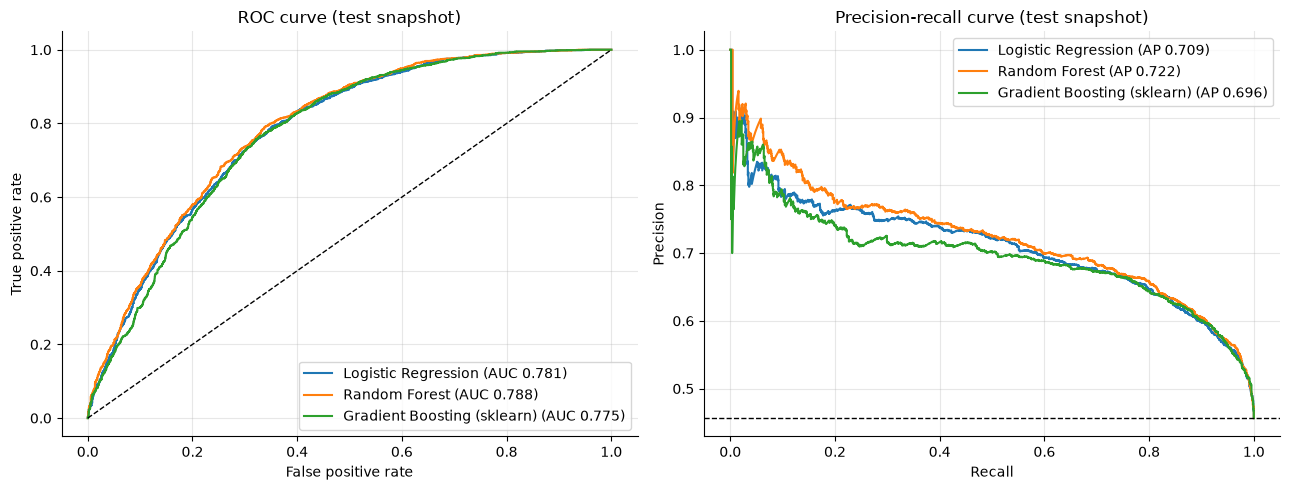

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in NAMES:
    fpr, tpr, _ = roc_curve(y_test, p_cal[n])
    ax[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_test, p_cal[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p_cal[n])
    ax[1].plot(rc, pr, label=f"{n} (AP {average_precision_score(y_test, p_cal[n]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve (test snapshot)"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), ls="--", c="k", lw=1); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curve (test snapshot)"); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIG}/16_roc_pr_curves.png", dpi=120); plt.show()

## 9. Calibration curves
A perfectly calibrated model follows the diagonal: among customers given a 70% churn probability, about 70% really churn. Dots show the raw model, the second line shows the calibrated version.

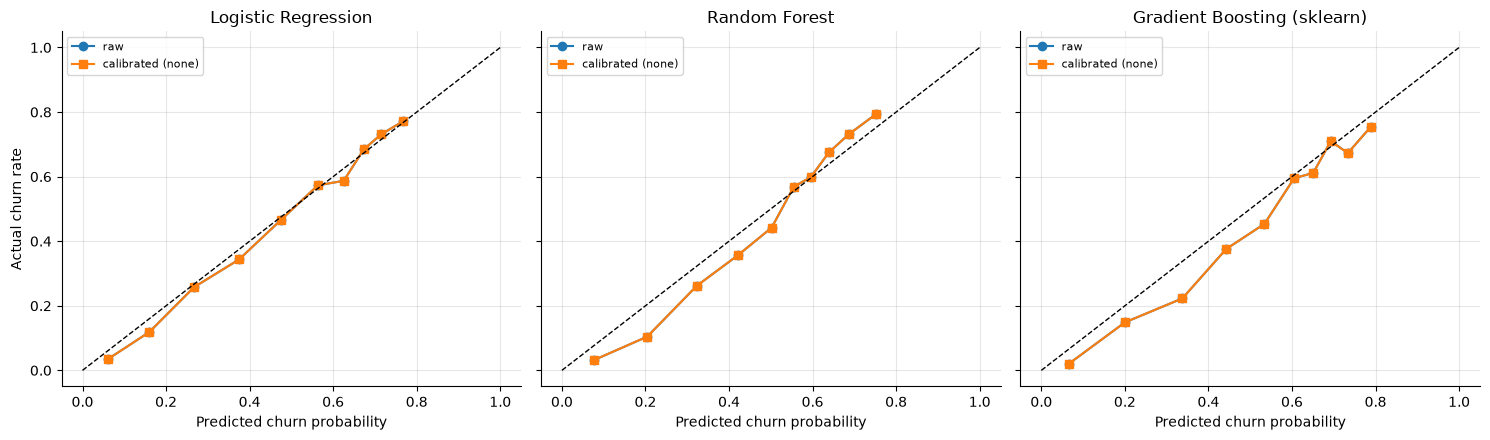

In [15]:
fig, ax = plt.subplots(1, len(NAMES), figsize=(5 * len(NAMES), 4.5), sharey=True)
for a, n in zip(np.atleast_1d(ax), NAMES):
    for p, lab, mk in ((p_raw[n], "raw", "o"), (p_cal[n], f"calibrated ({chosen[n]})", "s")):
        frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
        a.plot(mean_pred, frac, marker=mk, label=lab)
    a.plot([0, 1], [0, 1], "k--", lw=1)
    a.set_title(n); a.set_xlabel("Predicted churn probability"); a.legend(loc="upper left", fontsize=8)
np.atleast_1d(ax)[0].set_ylabel("Actual churn rate")
plt.tight_layout(); plt.savefig(f"{FIG}/17_calibration_curves.png", dpi=120); plt.show()

## 10. Looking closely at the best model
The model with the best cross-validated ROC-AUC (chosen in section 4, not on the test set) is examined in detail: how precision and recall trade off, how many churners the highest-risk customers capture, and where the model is weaker.

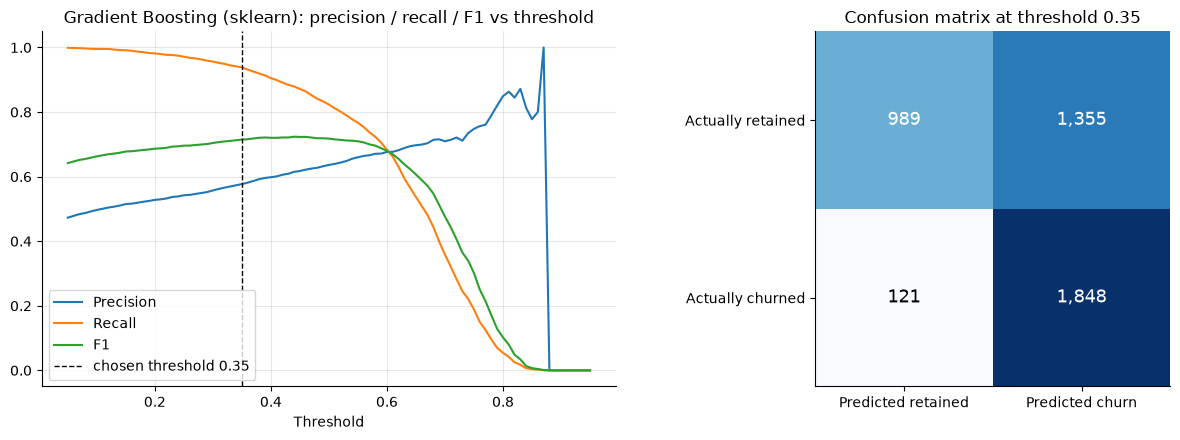

In [16]:
pb = p_cal[BEST]
tb = thr[BEST]
pred_b = (pb >= tb).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
grid = np.arange(0.05, 0.96, 0.01)
ax[0].plot(grid, [precision_score(y_test, (pb >= t).astype(int), zero_division=0) for t in grid], label="Precision")
ax[0].plot(grid, [recall_score(y_test, (pb >= t).astype(int)) for t in grid], label="Recall")
ax[0].plot(grid, [f1_score(y_test, (pb >= t).astype(int)) for t in grid], label="F1")
ax[0].axvline(tb, ls="--", c="k", lw=1, label=f"chosen threshold {tb:.2f}")
ax[0].set_xlabel("Threshold"); ax[0].set_title(f"{BEST}: precision / recall / F1 vs threshold"); ax[0].legend()

cm = confusion_matrix(y_test, pred_b)
im = ax[1].imshow(cm, cmap="Blues"); ax[1].grid(False)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Predicted retained", "Predicted churn"])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["Actually retained", "Actually churned"])
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[1].set_title(f"Confusion matrix at threshold {tb:.2f}")
plt.tight_layout(); plt.savefig(f"{FIG}/18_threshold_confusion.png", dpi=120); plt.show()

Decile 1 = the 10% of customers the model rates as highest risk


,Customers,Churners,ActualChurnRate,AvgPredicted,Cumulative % of churners found,Lift
Decile,,,,,,
1,432,326,0.755,0.789,16.557,1.653
2,431,290,0.673,0.734,31.285,1.474
3,431,306,0.710,0.693,46.826,1.555
4,431,263,0.610,0.651,60.183,1.337
5,432,258,0.597,0.605,73.286,1.308
6,431,195,0.452,0.534,83.189,0.991
7,431,162,0.376,0.443,91.417,0.823
8,431,96,0.223,0.337,96.293,0.488
9,431,64,0.148,0.200,99.543,0.325


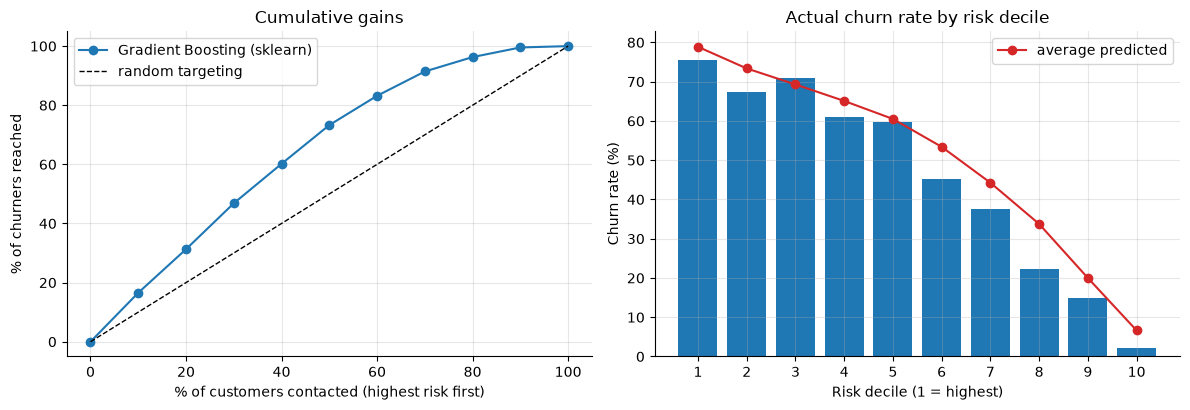

In [17]:
# gains / lift: how many churners are found if we contact only the highest-risk customers?
tmp = pd.DataFrame({"y": y_test, "p": pb}).sort_values("p", ascending=False).reset_index(drop=True)
tmp["Decile"] = pd.qcut(np.arange(len(tmp)), 10, labels=range(1, 11))
g = tmp.groupby("Decile", observed=True).agg(Customers=("y", "size"), Churners=("y", "sum"),
                                              ActualChurnRate=("y", "mean"), AvgPredicted=("p", "mean"))
g["Cumulative % of churners found"] = g["Churners"].cumsum() / g["Churners"].sum() * 100
g["Lift"] = g["ActualChurnRate"] / y_test.mean()
print("Decile 1 = the 10% of customers the model rates as highest risk")
display(g)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(0, 11) * 10
ax[0].plot(x, [0] + list(g["Cumulative % of churners found"]), marker="o", label=BEST)
ax[0].plot([0, 100], [0, 100], "k--", lw=1, label="random targeting")
ax[0].set_xlabel("% of customers contacted (highest risk first)"); ax[0].set_ylabel("% of churners reached")
ax[0].set_title("Cumulative gains"); ax[0].legend()
ax[1].bar(g.index.astype(str), g["ActualChurnRate"] * 100)
ax[1].plot(range(10), g["AvgPredicted"] * 100, "o-", c="tab:red", label="average predicted")
ax[1].set_xlabel("Risk decile (1 = highest)"); ax[1].set_ylabel("Churn rate (%)"); ax[1].set_title("Actual churn rate by risk decile")
ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/19_gains_deciles.png", dpi=120); plt.show()

top20 = g["Cumulative % of churners found"].iloc[1]

In [18]:
# where is the model weaker? performance by customer type
bucket = pd.cut(test["Frequency"], [0, 1, 2, 4, 10 ** 6], labels=["1 order", "2 orders", "3-4 orders", "5+ orders"])
rows = []
for lab in bucket.cat.categories:
    m = (bucket == lab).to_numpy()
    rows.append({"Customer group": lab, "Customers": int(m.sum()), "Actual churn rate": y_test[m].mean(),
                 "Avg predicted": pb[m].mean(),
                 "ROC-AUC": roc_auc_score(y_test[m], pb[m]) if len(set(y_test[m])) > 1 else np.nan})
by_group = pd.DataFrame(rows).set_index("Customer group")
display(by_group)

,Customers,Actual churn rate,Avg predicted,ROC-AUC
Customer group,,,,
1 order,1051,0.713,0.678,0.633
2 orders,741,0.599,0.634,0.628
3-4 orders,905,0.474,0.563,0.639
5+ orders,1616,0.215,0.301,0.787


## 11. Save results, models and a scoring helper

In [19]:
# 1) comparison table for the report
comparison = table_a.join(table_b, how="left", rsuffix=" (calib.)")
comparison.insert(0, "CV ROC-AUC (train)", cv_table["CV ROC-AUC (mean)"])
comparison.to_csv(f"{DATA}/model_comparison.csv")

# 2) test-snapshot predictions (used by the retention framework in Step 8)
pred = test[["CustomerID", "SnapshotDate", "Country", "Recency", "Frequency", "Monetary", "Churn", "Outcome_FutureSpend"]].copy()
for n in NAMES:
    pred[f"Proba_{n}"] = p_cal[n]
pred["ChurnProbability"] = pb
pred["PredictedChurn"] = pred_b
pred["RiskDecile"] = 11 - pd.qcut(pred["ChurnProbability"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
pred["RiskTier"] = np.select([pred["RiskDecile"] <= 2, pred["RiskDecile"] <= 5], ["High", "Medium"], default="Low")
pred["SnapshotDate"] = pred["SnapshotDate"].dt.strftime("%Y-%m-%d")
pred.to_csv(f"{DATA}/churn_predictions_test.csv", index=False)

# 3) fitted models + calibrators in one file
bundle = {"best": BEST, "features": X_COLS,
          "models": {n: {"pipeline": searches[n].best_estimator_, "method": chosen[n],
                         "calibrator": calibrators[n], "threshold": thr[n]} for n in NAMES}}
joblib.dump(bundle, f"{MODELS}/churn_models.joblib")

# 4) helper so any later notebook or the dashboard can score customers without repeating this code
HELPER = """\"\"\"Score customers with the churn models saved by 04_churn_models.ipynb.

    import churn_scoring as cs
    bundle = cs.load_bundle("models/churn_models.joblib")
    df["ChurnProbability"] = cs.predict_proba(bundle, df)      # df needs the Step 3 feature columns
    df["PredictedChurn"] = cs.predict_label(bundle, df)
\"\"\"
import joblib
import numpy as np


def load_bundle(path="models/churn_models.joblib"):
    return joblib.load(path)


def add_flags(df):
    df = df.copy()
    df["GapMissing"] = df["AvgGapDays"].isna().astype(int)
    df["StdGapMissing"] = df["StdGapDays"].isna().astype(int)
    return df


def _logit(s):
    s = np.clip(s, 1e-6, 1 - 1e-6)
    return np.log(s / (1 - s))


def predict_proba(bundle, df, model=None):
    m = bundle["models"][model or bundle["best"]]
    s = m["pipeline"].predict_proba(add_flags(df)[bundle["features"]])[:, 1]
    if m["method"] == "isotonic":
        p = m["calibrator"].predict(s)
    elif m["method"] == "sigmoid":
        p = m["calibrator"].predict_proba(_logit(s).reshape(-1, 1))[:, 1]
    else:
        p = s
    return np.clip(p, 0.001, 0.999)


def predict_label(bundle, df, model=None):
    m = bundle["models"][model or bundle["best"]]
    return (predict_proba(bundle, df, model) >= m["threshold"]).astype(int)
"""
with open(f"{MODELS}/churn_scoring.py", "w") as fh:
    fh.write(HELPER)

# 5) prove the helper gives exactly the same answers as this notebook
import importlib, sys
sys.path.insert(0, MODELS)
import churn_scoring as cs
importlib.reload(cs)
check_bundle = cs.load_bundle(f"{MODELS}/churn_models.joblib")
same = all(np.allclose(cs.predict_proba(check_bundle, test, n), p_cal[n]) for n in NAMES)
print("Scoring helper reproduces the notebook's probabilities exactly:", same)
assert same

for f in (f"{DATA}/model_comparison.csv", f"{DATA}/churn_predictions_test.csv", f"{MODELS}/churn_models.joblib", f"{MODELS}/churn_scoring.py"):
    print(f"saved {f}  ({os.path.getsize(f) / 1e6:.2f} MB)")

Scoring helper reproduces the notebook's probabilities exactly: True
saved data/model_comparison.csv  (0.00 MB)
saved data/churn_predictions_test.csv  (0.61 MB)
saved models/churn_models.joblib  (3.17 MB)
saved models/churn_scoring.py  (0.00 MB)


## 12. Summary of findings

In [20]:
a = table_a.loc[BEST]
lines = [
    f"Best model (by cross-validation): {BEST}; test ROC-AUC {a['ROC-AUC']:.3f} (95% CI {a['ROC-AUC 95% CI']}), PR-AUC {a['PR-AUC']:.3f}.",
    f"Ranking of models by test ROC-AUC: " + ", ".join(f"{n} {table_a.loc[n, 'ROC-AUC']:.3f}" for n in table_a.drop('Dummy (average rate)').sort_values('ROC-AUC', ascending=False).index) + ".",
    f"At the chosen threshold ({a['Threshold']:.2f}) the best model reaches F1 {a['F1']:.3f}, precision {a['Precision']:.3f}, recall {a['Recall']:.3f}.",
    f"Contacting only the 20% highest-risk customers reaches {top20:.0f}% of all churners (random targeting would reach 20%).",
    f"Calibration: ECE for {BEST} changed from {table_b.loc[BEST, 'ECE raw']:.3f} (raw) to {table_b.loc[BEST, 'ECE calibrated']:.3f} (calibrated) using '{chosen[BEST]}'.",
    f"Hardest group: customers with 1 order (ROC-AUC {by_group.loc['1 order', 'ROC-AUC']:.3f}); easiest: {by_group['ROC-AUC'].idxmax()} ({by_group['ROC-AUC'].max():.3f}).",
]
print("KEY FINDINGS")
print("=" * 60)
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}")
with open("model_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(f"{i}. {l}" for i, l in enumerate(lines, 1)))
print("\nSaved model_summary.txt")

KEY FINDINGS
1. Best model (by cross-validation): Gradient Boosting (sklearn); test ROC-AUC 0.775 (95% CI 0.761 - 0.787), PR-AUC 0.696.
2. Ranking of models by test ROC-AUC: Random Forest 0.788, Logistic Regression 0.781, Gradient Boosting (sklearn) 0.775.
3. At the chosen threshold (0.35) the best model reaches F1 0.715, precision 0.577, recall 0.939.
4. Contacting only the 20% highest-risk customers reaches 31% of all churners (random targeting would reach 20%).
5. Calibration: ECE for Gradient Boosting (sklearn) changed from 0.050 (raw) to 0.050 (calibrated) using 'none'.
6. Hardest group: customers with 1 order (ROC-AUC 0.633); easiest: 5+ orders (0.787).

Saved model_summary.txt


## Next step
Step 5 explains the best model with **SHAP** to find the behavioural factors behind churn (Objective 3). Load the saved bundle and the data like this:

```python
import sys; sys.path.insert(0, "models")
import churn_scoring as cs
bundle = cs.load_bundle("models/churn_models.joblib")
pipe = bundle["models"][bundle["best"]]["pipeline"]
```

Important for the report:
- The test snapshot is a single date, so say that results are for one 150-day outcome window.
- A churn probability from this notebook is a *calibrated* probability, which is what Step 8 needs to weigh churn risk against customer value.